# Crime Hotspot Detection – Los Angeles

**Project:** Crime Hotspot Detection  
**Dataset:** LAPD Crime Data from 2020 to 2024  
**Objective:** Identify geographic areas with concentrated reported crime, analyze their patterns, and create clear visualizations to support evidence-based safety planning.

> **Data-use reminder:** The supplied dataset must not be uploaded publicly to GitHub, Kaggle, or any other public platform. Keep the CSV local and include it only in the private submission ZIP if permitted by the project coordinator.

This notebook follows the same step-by-step workflow as the Fuel Efficiency notebook: library imports, dataset loading, overview, missing-value handling, EDA, outlier checks, feature engineering, model building, evaluation, and visualizations.

**Important interpretation:** Hotspots in this notebook are areas with a high concentration of *historically reported incidents*. They are not proof that a location is unsafe, and the model does not predict that a specific person will commit a crime. Use results only as area-level analytical indicators.

# Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    silhouette_score, mean_absolute_error, mean_squared_error
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42

# Load Dataset

Place `LA_Crime_Data_from_2020_to_2024.csv` in the same folder as this notebook. The dataset is large, so only columns needed for this analysis are loaded. Set `SAMPLE_ROWS` to an integer for a quick test run, or keep it as `None` to load all available records.

In [2]:
file_path = "LA_Crime_Data_from_2020_to_2024.csv"

use_columns = [
    "DR_NO", "DATE OCC", "TIME OCC", "AREA", "AREA NAME",
    "Part 1-2", "Crm Cd", "Crm Cd Desc", "Vict Age",
    "Weapon Used Cd", "LAT", "LON"
]

SAMPLE_ROWS = None  # Example: 200000 for a faster test; None loads all rows

if SAMPLE_ROWS is None:
    df = pd.read_csv(file_path, usecols=use_columns, low_memory=False)
else:
    df = pd.read_csv(file_path, usecols=use_columns, nrows=SAMPLE_ROWS, low_memory=False)

print("Dataset loaded successfully")

Dataset loaded successfully


# Data Overview

In [3]:
df.head()

,DR_NO,DATE OCC,TIME OCC,AREA,AREA NAME,Part 1-2,Crm Cd,Crm Cd Desc,Vict Age,Weapon Used Cd,LAT,LON
0,190326475,03/01/2020 12:00:00 AM,2130,7,Wilshire,1,510,VEHICLE - STOLEN,0,NaN,34.0375,-118.3506
1,200106753,02/08/2020 12:00:00 AM,1800,1,Central,1,330,BURGLARY FROM VEHICLE,47,NaN,34.0444,-118.2628
2,200320258,11/04/2020 12:00:00 AM,1700,3,Southwest,1,480,BIKE - STOLEN,19,NaN,34.0210,-118.3002
3,200907217,03/10/2020 12:00:00 AM,2037,9,Van Nuys,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),19,NaN,34.1576,-118.4387
4,220614831,08/17/2020 12:00:00 AM,1200,6,Hollywood,2,354,THEFT OF IDENTITY,28,NaN,34.0944,-118.3277


In [4]:
df.shape

(901357, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 901357 entries, 0 to 901356
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   DR_NO           901357 non-null  int64  
 1   DATE OCC        901357 non-null  object 
 2   TIME OCC        901357 non-null  int64  
 3   AREA            901357 non-null  int64  
 4   AREA NAME       901357 non-null  object 
 5   Part 1-2        901357 non-null  int64  
 6   Crm Cd          901357 non-null  int64  
 7   Crm Cd Desc     901357 non-null  object 
 8   Vict Age        901357 non-null  int64  
 9   Weapon Used Cd  312268 non-null  float64
 10  LAT             901357 non-null  float64
 11  LON             901357 non-null  float64
dtypes: float64(3), int64(6), object(3)
memory usage: 82.5+ MB


In [6]:
df.columns

Index(['DR_NO', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Part 1-2',
       'Crm Cd', 'Crm Cd Desc', 'Vict Age', 'Weapon Used Cd', 'LAT', 'LON'],
      dtype='object')

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DR_NO,901357.0,NaN,NaN,NaN,217818488.834397,11746566.269259,817.0,210320927.0,220416646.0,230320234.0,249904551.0
DATE OCC,901357,1511,12/02/2022 12:00:00 AM,1132,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TIME OCC,901357.0,NaN,NaN,NaN,1336.869943,653.074344,1.0,900.0,1415.0,1900.0,2359.0
AREA,901357.0,NaN,NaN,NaN,10.698448,6.102033,1.0,5.0,11.0,16.0,21.0
AREA NAME,901357,21,Central,61416,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Part 1-2,901357.0,NaN,NaN,NaN,1.411132,0.492039,1.0,1.0,1.0,2.0,2.0
Crm Cd,901357.0,NaN,NaN,NaN,500.841333,207.63664,110.0,331.0,442.0,626.0,956.0
Crm Cd Desc,901357,139,VEHICLE - STOLEN,96751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vict Age,901357.0,NaN,NaN,NaN,29.626145,21.839342,-4.0,0.0,31.0,45.0,120.0
Weapon Used Cd,312268.0,NaN,NaN,NaN,363.443555,123.69913,101.0,310.0,400.0,400.0,516.0


# Handling Missing Values

In [8]:
df.isnull().sum().sort_values(ascending=False)

Weapon Used Cd    589089
DR_NO                  0
DATE OCC               0
TIME OCC               0
AREA                   0
AREA NAME              0
Part 1-2               0
Crm Cd                 0
Crm Cd Desc            0
Vict Age               0
LAT                    0
LON                    0
dtype: int64

For geographic hotspot detection, latitude and longitude are essential. Records without valid coordinates are removed. Missing descriptive values are retained as `Unknown` where useful; missing victim age is not treated as zero.

In [9]:
df["DATE OCC"] = pd.to_datetime(df["DATE OCC"], errors="coerce")
df["TIME OCC"] = pd.to_numeric(df["TIME OCC"], errors="coerce")

df = df.dropna(subset=["DATE OCC", "LAT", "LON"]).copy()

# Remove invalid / placeholder coordinates outside the Los Angeles study area
df = df[
    df["LAT"].between(33.0, 35.0) &
    df["LON"].between(-119.5, -117.0)
].copy()

for col in ["AREA NAME", "Crm Cd Desc"]:
    df[col] = df[col].fillna("Unknown")

df["Vict Age"] = pd.to_numeric(df["Vict Age"], errors="coerce")
df.loc[~df["Vict Age"].between(0, 100), "Vict Age"] = np.nan

print("Rows after basic cleaning:", len(df))
print("Missing values after cleaning:")
display(df.isnull().sum())

Rows after basic cleaning: 899094
Missing values after cleaning:


DR_NO                  0
DATE OCC               0
TIME OCC               0
AREA                   0
AREA NAME              0
Part 1-2               0
Crm Cd                 0
Crm Cd Desc            0
Vict Age              90
Weapon Used Cd    587659
LAT                    0
LON                    0
dtype: int64

# Feature Engineering

In [10]:
df["Year"] = df["DATE OCC"].dt.year
df["Month"] = df["DATE OCC"].dt.month
df["Day"] = df["DATE OCC"].dt.day
df["DayOfWeek"] = df["DATE OCC"].dt.dayofweek
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)

# TIME OCC is stored as HHMM (for example, 1830 = 6:30 PM)
df["Hour"] = (df["TIME OCC"].fillna(0).astype(int) // 100).clip(0, 23)
df["IsNight"] = df["Hour"].between(20, 23).astype(int) | df["Hour"].between(0, 5).astype(int)
df["IsNight"] = df["IsNight"].astype(int)

# Rounded coordinates create small geographic cells for area-level aggregation
GRID_DECIMALS = 3
df["GridLat"] = df["LAT"].round(GRID_DECIMALS)
df["GridLon"] = df["LON"].round(GRID_DECIMALS)

df[["DATE OCC", "Hour", "DayOfWeek", "IsWeekend", "GridLat", "GridLon"]].head()

,DATE OCC,Hour,DayOfWeek,IsWeekend,GridLat,GridLon
0,2020-03-01,21,6,1,34.038,-118.351
1,2020-02-08,18,5,1,34.044,-118.263
2,2020-11-04,17,2,0,34.021,-118.300
3,2020-03-10,20,1,0,34.158,-118.439
4,2020-08-17,12,0,0,34.094,-118.328


# Exploratory Data Analysis (EDA)

## Crime Records by Year

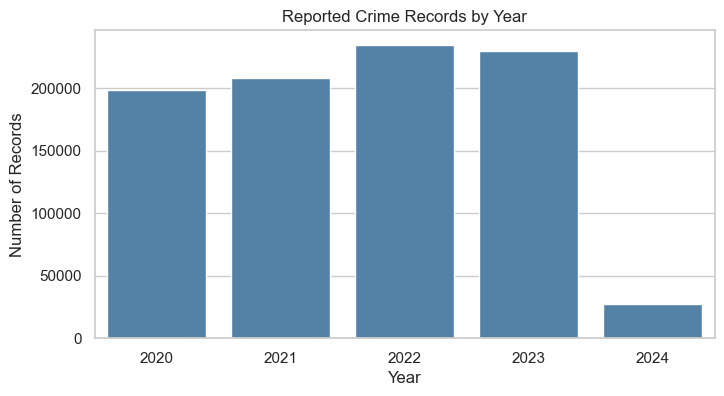

In [11]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="Year", order=sorted(df["Year"].dropna().unique()), color="steelblue")
plt.title("Reported Crime Records by Year")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

## Top 15 Crime Categories

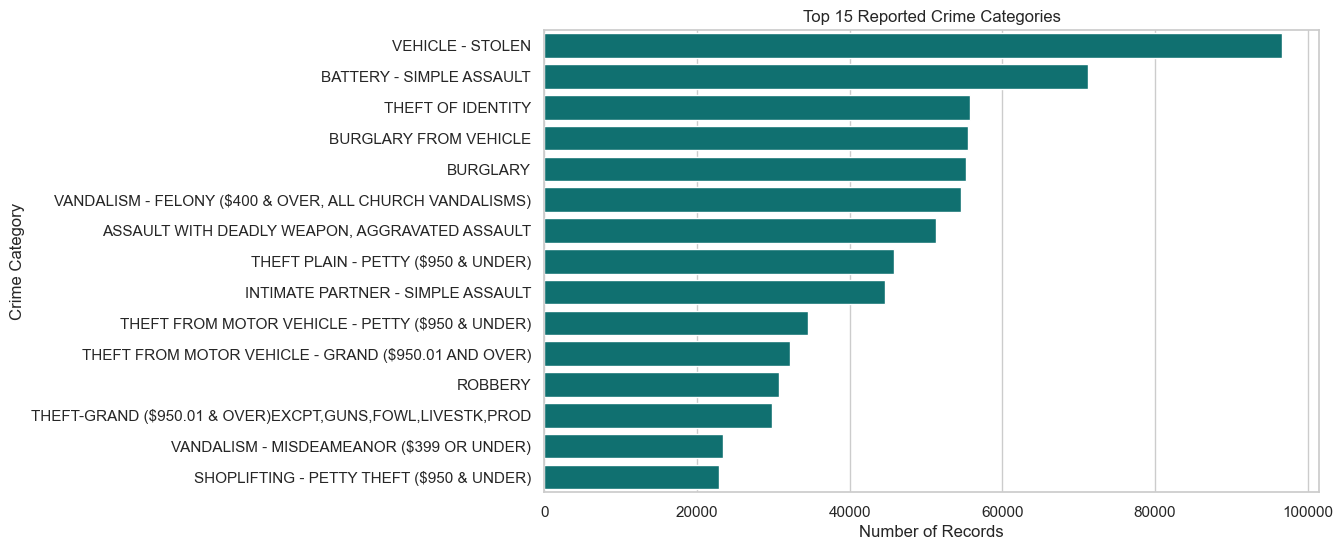

In [12]:
top_crimes = df["Crm Cd Desc"].value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=top_crimes.values, y=top_crimes.index, color="teal")
plt.title("Top 15 Reported Crime Categories")
plt.xlabel("Number of Records")
plt.ylabel("Crime Category")
plt.show()

## Crime Distribution by Hour

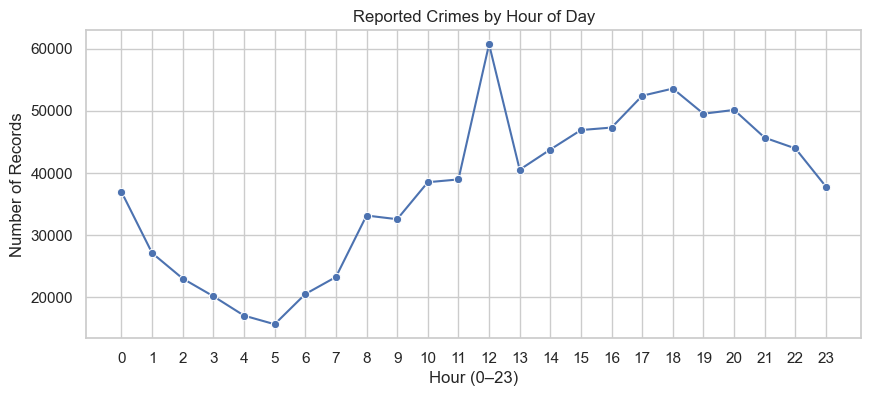

In [13]:
hour_counts = df["Hour"].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sns.lineplot(x=hour_counts.index, y=hour_counts.values, marker="o")
plt.title("Reported Crimes by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Records")
plt.xticks(range(24))
plt.show()

## Crime Distribution by Day of Week

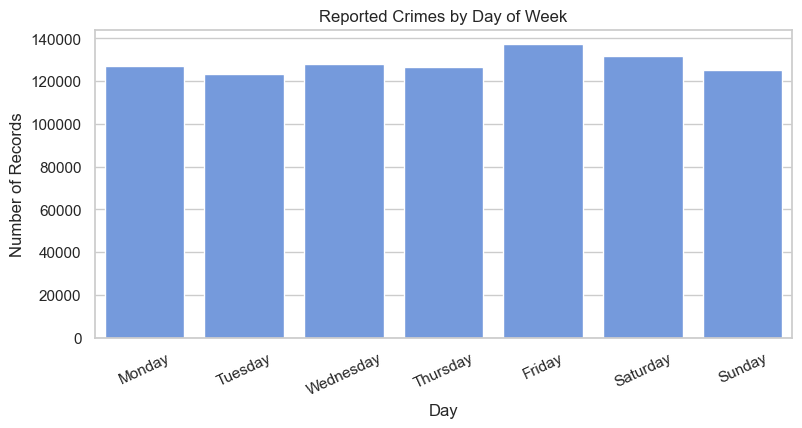

In [14]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_counts = df["DayOfWeek"].value_counts().reindex(range(7), fill_value=0)
plt.figure(figsize=(9, 4))
sns.barplot(x=day_names, y=day_counts.values, color="cornflowerblue")
plt.title("Reported Crimes by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Records")
plt.xticks(rotation=25)
plt.show()

## Top 15 LAPD Areas by Reported Records

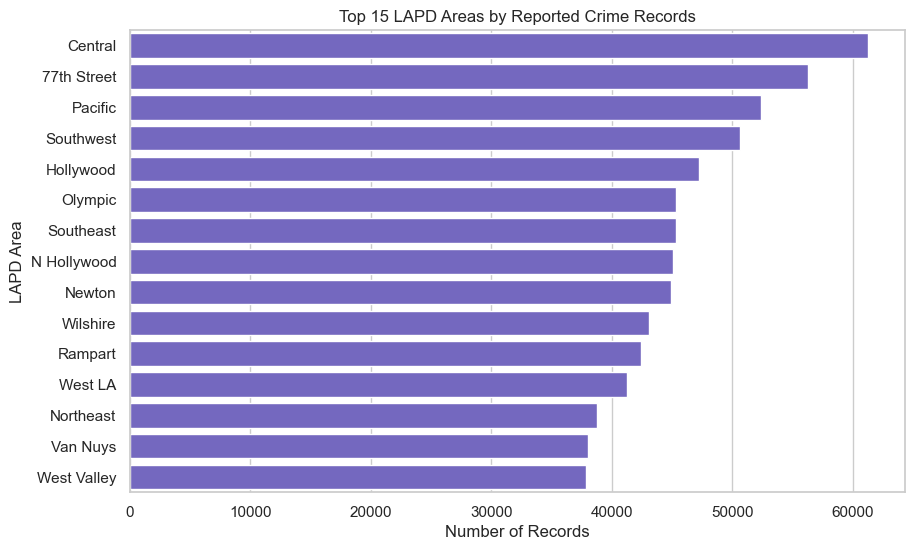

In [15]:
area_counts = df["AREA NAME"].value_counts().head(15)
plt.figure(figsize=(10, 6))
sns.barplot(x=area_counts.values, y=area_counts.index, color="slateblue")
plt.title("Top 15 LAPD Areas by Reported Crime Records")
plt.xlabel("Number of Records")
plt.ylabel("LAPD Area")
plt.show()

## Correlation Heatmap

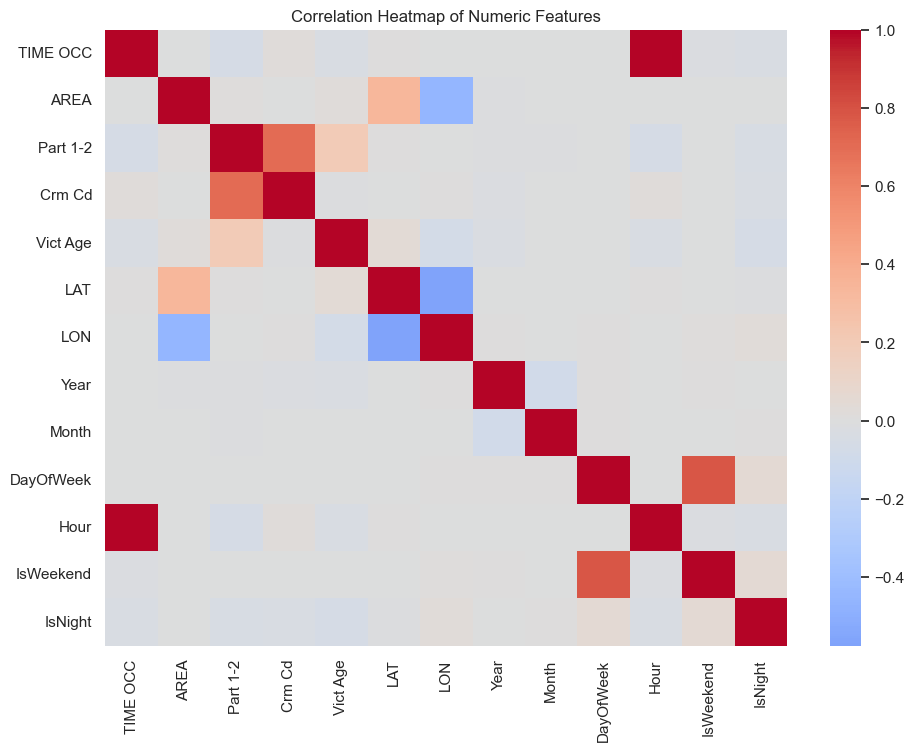

In [16]:
numeric_cols = ["TIME OCC", "AREA", "Part 1-2", "Crm Cd", "Vict Age", "LAT", "LON",
                "Year", "Month", "DayOfWeek", "Hour", "IsWeekend", "IsNight"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

# Geographic Hotspot Analysis

The first hotspot method is **DBSCAN**, a density-based clustering algorithm. It groups nearby incident coordinates into dense geographic clusters and labels isolated points as noise. Coordinates are converted to radians and the Haversine distance metric is used so that the neighborhood radius is interpreted in kilometers.

In [17]:
from sklearn.metrics.pairwise import haversine_distances

# Use a manageable random sample for DBSCAN if the complete dataset is very large.
MAX_DBSCAN_ROWS = 100000
geo_data = df[["LAT", "LON"]].dropna()
if len(geo_data) > MAX_DBSCAN_ROWS:
    geo_sample = geo_data.sample(MAX_DBSCAN_ROWS, random_state=RANDOM_STATE)
else:
    geo_sample = geo_data.copy()

coords_radians = np.radians(geo_sample[["LAT", "LON"]].to_numpy())

# Approximate neighborhood radius: 0.7 km
EARTH_RADIUS_KM = 6371.0088
EPS_KM = 0.7
dbscan = DBSCAN(
    eps=EPS_KM / EARTH_RADIUS_KM,
    min_samples=30,
    metric="haversine",
    algorithm="ball_tree"
)

geo_sample = geo_sample.copy()
geo_sample["Cluster"] = dbscan.fit_predict(coords_radians)

print("Number of identified clusters:", geo_sample.loc[geo_sample["Cluster"] != -1, "Cluster"].nunique())
print("Noise records:", (geo_sample["Cluster"] == -1).sum())

Number of identified clusters: 6
Noise records: 1051


## DBSCAN Hotspot Summary

In [18]:
hotspot_summary = (
    geo_sample[geo_sample["Cluster"] != -1]
    .groupby("Cluster")
    .agg(
        Incident_Count=("Cluster", "size"),
        Center_Lat=("LAT", "mean"),
        Center_Lon=("LON", "mean")
    )
    .sort_values("Incident_Count", ascending=False)
)
hotspot_summary.head(15)

,Incident_Count,Center_Lat,Center_Lon
Cluster,,,
0,96172,34.077914,-118.354020
1,1834,33.735767,-118.292519
2,588,34.256447,-118.298205
3,280,34.041969,-118.535535
4,40,34.304042,-118.508400
5,35,34.286180,-118.578351


## Visualize Geographic Hotspots

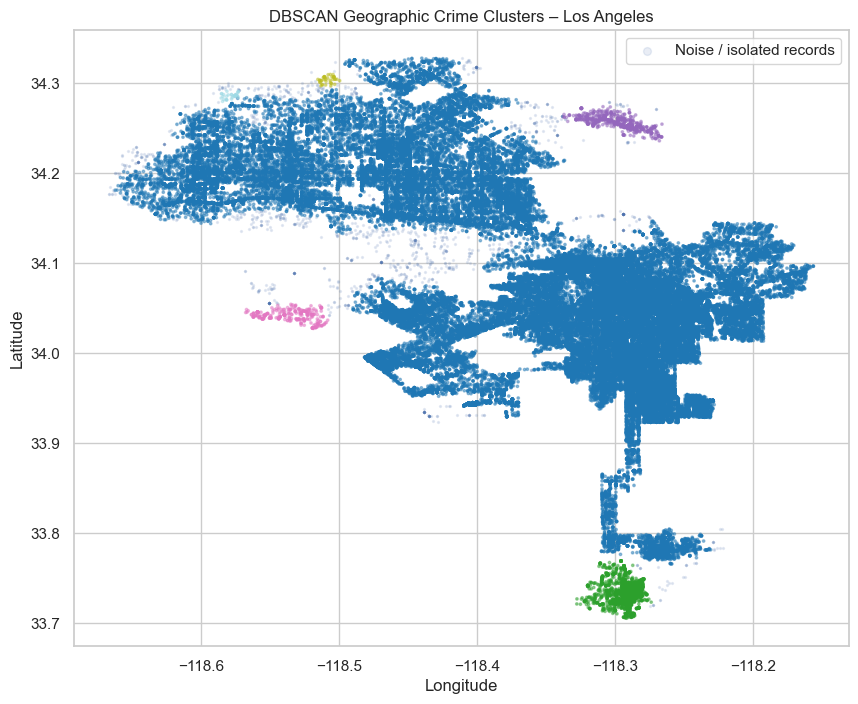

In [19]:
plt.figure(figsize=(10, 8))
noise = geo_sample[geo_sample["Cluster"] == -1]
clusters = geo_sample[geo_sample["Cluster"] != -1]

plt.scatter(noise["LON"], noise["LAT"], s=2, alpha=0.12, label="Noise / isolated records")
scatter = plt.scatter(
    clusters["LON"], clusters["LAT"],
    c=clusters["Cluster"], cmap="tab20", s=3, alpha=0.45
)
plt.title("DBSCAN Geographic Crime Clusters – Los Angeles")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=4)
plt.show()

# Grid-Based Hotspot Model

For an interpretable area-level model, incidents are grouped into rounded latitude/longitude grid cells. A cell is labelled a high-volume hotspot when its historical incident count is at or above the 90th percentile of cell counts. A Random Forest classifier is then trained using area characteristics (time-of-day mix, weekend share, crime-category diversity, serious-crime share, and available victim/weapon indicators), while the total incident count is excluded from the model inputs to avoid directly giving the answer to the classifier.

This is a retrospective classification of historically high-volume cells, not a forecast of future crime.

In [20]:
# Create one row per geographic grid cell
grid = df.groupby(["GridLat", "GridLon"]).agg(
    Incident_Count=("DR_NO", "count"),
    Unique_Crime_Categories=("Crm Cd", "nunique"),
    Weekend_Share=("IsWeekend", "mean"),
    Night_Share=("IsNight", "mean"),
    Serious_Crime_Share=("Part 1-2", lambda x: (x == 1).mean()),
    Victim_Age_Mean=("Vict Age", "mean"),
    Weapon_Reported_Share=("Weapon Used Cd", lambda x: x.notna().mean()),
    Mean_Hour=("Hour", "mean"),
    Area_Name=("AREA NAME", lambda x: x.mode().iloc[0] if not x.mode().empty else "Unknown")
).reset_index()

grid["Victim_Age_Mean"] = grid["Victim_Age_Mean"].fillna(grid["Victim_Age_Mean"].median())

hotspot_threshold = grid["Incident_Count"].quantile(0.90)
grid["Hotspot"] = (grid["Incident_Count"] >= hotspot_threshold).astype(int)

print("Grid cells:", len(grid))
print("90th percentile incident threshold:", round(hotspot_threshold, 2))
print(grid["Hotspot"].value_counts())
grid.head()

Grid cells: 46957
90th percentile incident threshold: 45.0
Hotspot
0    42151
1     4806
Name: count, dtype: int64


,GridLat,GridLon,Incident_Count,Unique_Crime_Categories,Weekend_Share,Night_Share,Serious_Crime_Share,Victim_Age_Mean,Weapon_Reported_Share,Mean_Hour,Area_Name,Hotspot
0,33.706,-118.293,16,11,0.312500,0.187500,0.625000,43.312500,0.500000,13.937500,Harbor,0
1,33.706,-118.292,2,1,0.500000,0.000000,0.000000,31.500000,0.000000,10.000000,Harbor,0
2,33.706,-118.291,4,4,0.500000,0.500000,0.250000,45.750000,0.500000,10.000000,Harbor,0
3,33.707,-118.294,39,20,0.358974,0.282051,0.564103,29.000000,0.589744,13.179487,Harbor,0
4,33.707,-118.293,11,6,0.181818,0.545455,0.363636,21.545455,0.363636,18.090909,Harbor,0


## Hotspot Distribution

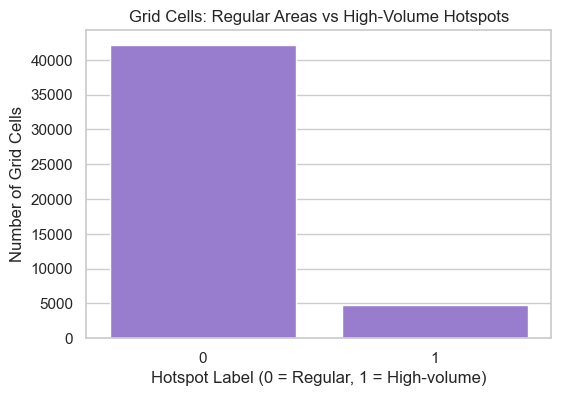

In [21]:
plt.figure(figsize=(6, 4))
sns.countplot(data=grid, x="Hotspot", color="mediumpurple")
plt.title("Grid Cells: Regular Areas vs High-Volume Hotspots")
plt.xlabel("Hotspot Label (0 = Regular, 1 = High-volume)")
plt.ylabel("Number of Grid Cells")
plt.show()

# Feature Selection

In [22]:
feature_cols = [
    "Unique_Crime_Categories",
    "Weekend_Share",
    "Night_Share",
    "Serious_Crime_Share",
    "Victim_Age_Mean",
    "Weapon_Reported_Share",
    "Mean_Hour"
]

X = grid[feature_cols].replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))
y = grid["Hotspot"]

print("Selected Features:", feature_cols)
print("Feature matrix shape:", X.shape)

Selected Features: ['Unique_Crime_Categories', 'Weekend_Share', 'Night_Share', 'Serious_Crime_Share', 'Victim_Age_Mean', 'Weapon_Reported_Share', 'Mean_Hour']
Feature matrix shape: (46957, 7)


# Train Test Split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 37565
Testing records: 9392


# Model Training – Random Forest Classifier

In [24]:
rf_model = RandomForestClassifier(
    n_estimators=250,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Model Evaluation

In [25]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

if y_test.nunique() == 2:
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.9634
Precision: 0.7569
Recall   : 0.9459
F1 Score : 0.8409
ROC-AUC  : 0.9929

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.97      0.98      8431
           1       0.76      0.95      0.84       961

    accuracy                           0.96      9392
   macro avg       0.88      0.96      0.91      9392
weighted avg       0.97      0.96      0.97      9392



## Confusion Matrix

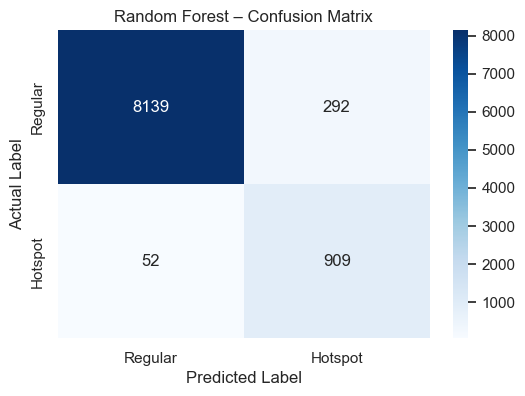

In [26]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Regular", "Hotspot"],
            yticklabels=["Regular", "Hotspot"])
plt.title("Random Forest – Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## Feature Importance

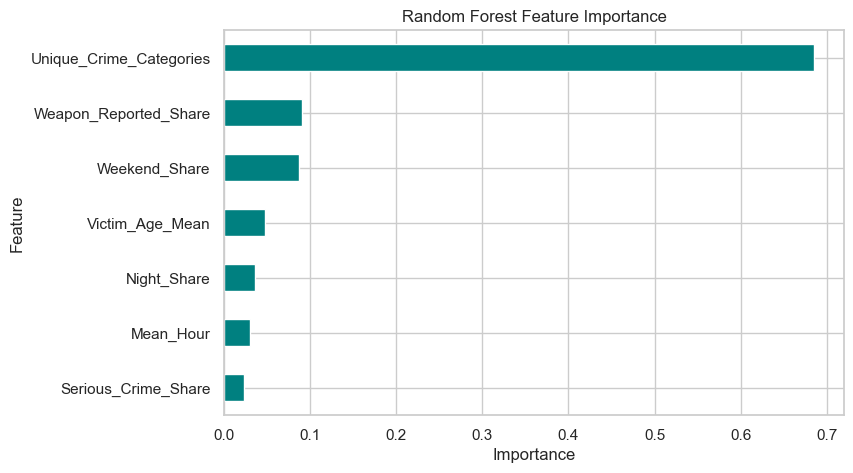

In [27]:
importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
plt.figure(figsize=(8, 5))
importance.plot(kind="barh", color="teal")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# Compare Clustering Approaches

K-Means is included as a comparison method. It partitions the sampled incident coordinates into a chosen number of geographic groups. Unlike DBSCAN, K-Means assigns every sampled record to a cluster and requires the number of clusters to be selected in advance. The cluster labels are not equivalent to a risk score.

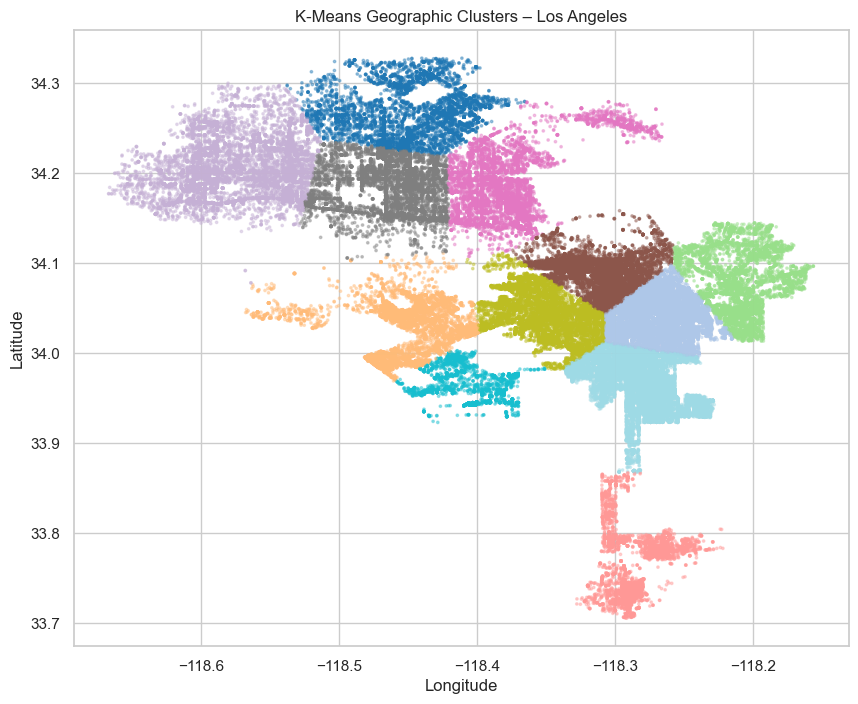

In [28]:
N_CLUSTERS = 12
kmeans_sample = geo_sample[["LAT", "LON"]].copy()
scaler_geo = StandardScaler()
scaled_coords = scaler_geo.fit_transform(kmeans_sample[["LAT", "LON"]])

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init=10)
kmeans_sample["KMeans_Cluster"] = kmeans.fit_predict(scaled_coords)

plt.figure(figsize=(10, 8))
plt.scatter(kmeans_sample["LON"], kmeans_sample["LAT"],
            c=kmeans_sample["KMeans_Cluster"], cmap="tab20", s=3, alpha=0.4)
plt.title("K-Means Geographic Clusters – Los Angeles")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# Interactive Hotspot Map (Optional)

The following cell creates an interactive Folium map using aggregated grid-cell centers, not individual incident addresses. If Folium is not installed, run `pip install folium` in your environment and rerun the cell.

In [29]:
try:
    import folium
    from folium.plugins import HeatMap

    center = [grid["GridLat"].mean(), grid["GridLon"].mean()]
    crime_map = folium.Map(location=center, zoom_start=10, tiles="CartoDB positron")

    heat_data = grid[["GridLat", "GridLon", "Incident_Count"]].values.tolist()
    HeatMap(heat_data, radius=14, blur=18, min_opacity=0.25).add_to(crime_map)

    # Add markers for the highest-volume cells only
    for _, row in grid.nlargest(30, "Incident_Count").iterrows():
        folium.CircleMarker(
            location=[row["GridLat"], row["GridLon"]],
            radius=5,
            popup=f"Aggregated incidents: {int(row['Incident_Count'])}",
            color="red",
            fill=True,
            fill_opacity=0.65
        ).add_to(crime_map)

    display(crime_map)
except ImportError:
    print("Folium is not installed. Run: pip install folium")

Folium is not installed. Run: pip install folium


# Generate Hotspot Output

In [30]:
grid["Predicted_Hotspot"] = rf_model.predict(X)
grid["Hotspot_Probability"] = rf_model.predict_proba(X)[:, 1]

hotspot_output = grid.sort_values(
    ["Predicted_Hotspot", "Hotspot_Probability", "Incident_Count"],
    ascending=[False, False, False]
)

hotspot_output[[
    "GridLat", "GridLon", "Incident_Count",
    "Predicted_Hotspot", "Hotspot_Probability", "Area_Name"
]].head(20)

,GridLat,GridLon,Incident_Count,Predicted_Hotspot,Hotspot_Probability,Area_Name
6219,33.977,-118.372,298,1,0.995087,Pacific
10510,34.017,-118.262,354,1,0.994266,Newton
10809,34.019,-118.201,162,1,0.994103,Hollenbeck
1004,33.760,-118.293,116,1,0.994070,Harbor
44573,34.276,-118.514,473,1,0.993951,Devonshire
25263,34.116,-118.184,245,1,0.993738,Northeast
6137,33.976,-118.373,595,1,0.993661,Pacific
30919,34.172,-118.385,123,1,0.993582,N Hollywood
29401,34.161,-118.510,70,1,0.993562,West Valley
44295,34.273,-118.427,190,1,0.993538,Foothill


In [31]:
# Save aggregated outputs only. Do not publish the source dataset.
hotspot_output.to_csv("la_crime_hotspot_grid_results.csv", index=False)
print("Aggregated hotspot results saved.")

Aggregated hotspot results saved.


# Project Findings and Recommendations

Use the actual outputs produced above to complete this section after running the notebook.

1. Identify the LAPD areas and geographic grid cells with the largest historical incident concentrations.
2. Describe the crime categories and time periods that contribute most to the observed patterns.
3. Compare DBSCAN's density-based clusters with K-Means' fixed-number geographic partitions.
4. Report the Random Forest accuracy, precision, recall, F1-score, and ROC-AUC. Pay particular attention to recall and precision because hotspot classes may be imbalanced.
5. Explain limitations: reported incidents are not all incidents; the dataset reflects reporting and recording practices; rounded coordinates reduce spatial precision; historical concentration does not establish future risk or causation.
6. Recommend that any operational decisions be reviewed by qualified local authorities and supported by current, contextual information. Avoid profiling individuals or treating an area-level result as evidence about a person.

# Conclusion

This project applies exploratory data analysis, geographic density clustering, grid-based aggregation, and Random Forest classification to LAPD crime records from 2020–2024. The resulting maps and tables summarize historical incident concentrations at an area level. Final conclusions should be based on the metrics and visualizations generated from the complete dataset, with the limitations stated clearly.

# Requirements

In [32]:
# If required, install the dependencies in your notebook environment:
# %pip install pandas numpy matplotlib seaborn scikit-learn folium

**Submission checklist**
- [ ] Run all notebook cells from top to bottom.
- [ ] Check the evaluation metrics and complete the findings section using actual results.
- [ ] Keep the original CSV private; do not upload it to public repositories.
- [ ] Save the notebook and final report / PowerPoint.
- [ ] Put the required submission files in a ZIP folder.